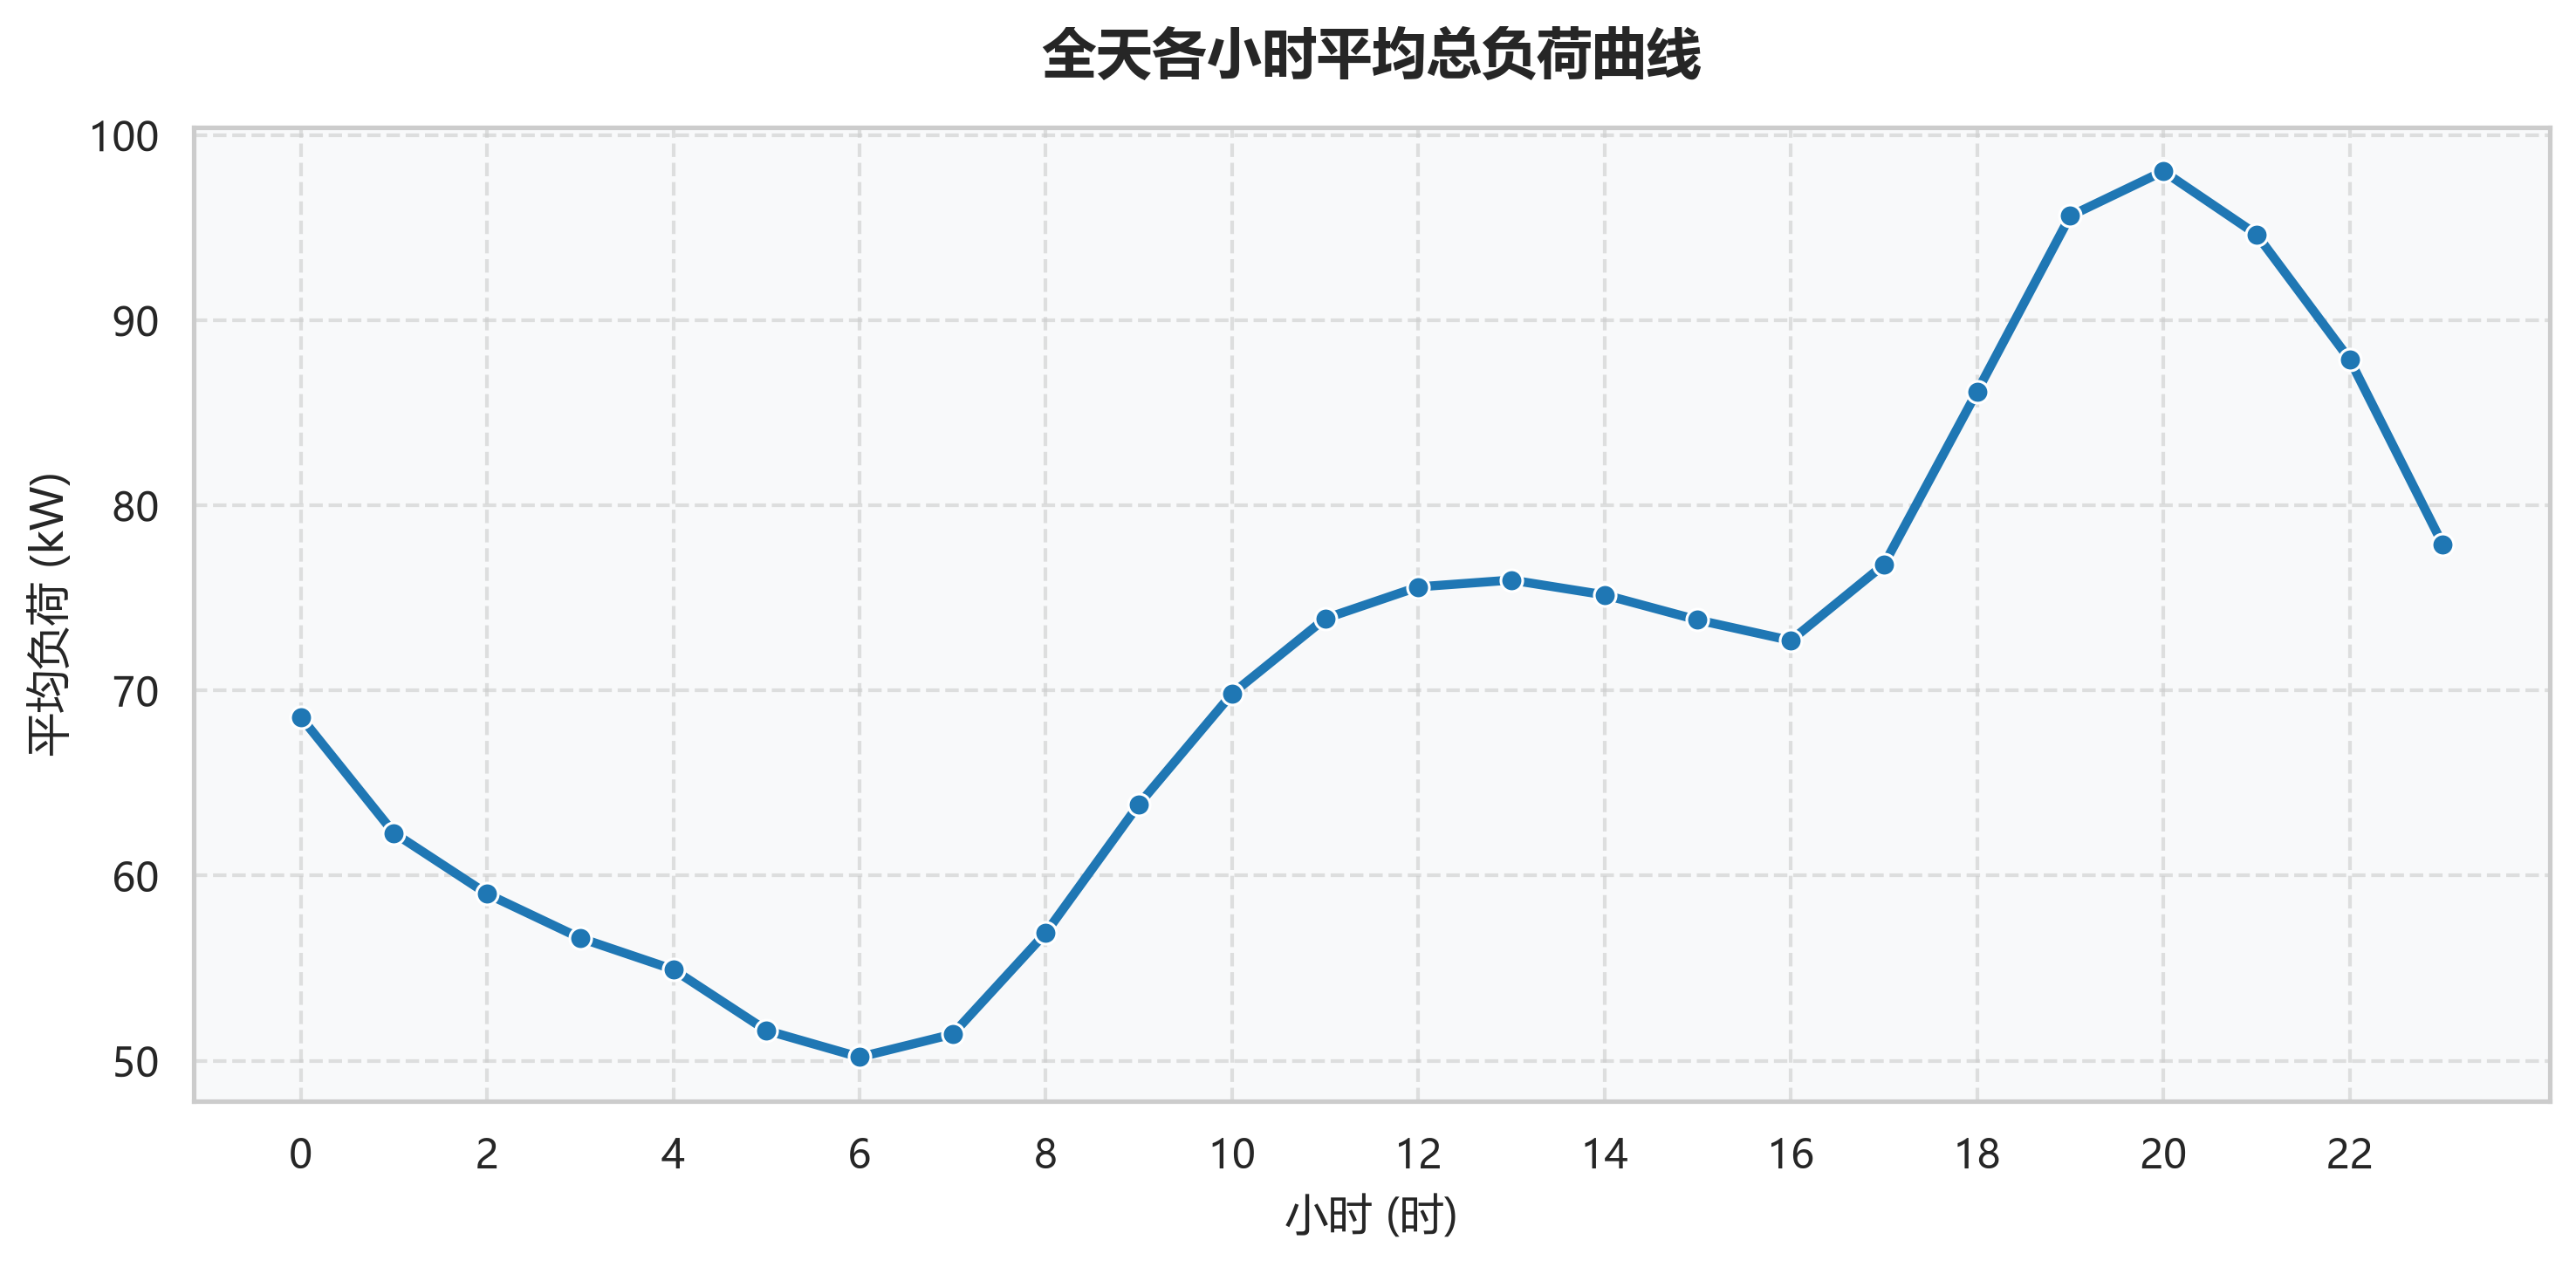

C:\Users\22973\AppData\Local\Temp\ipykernel_25788\2379895506.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=days, y=weekly_avg.values, palette='Blues_d')


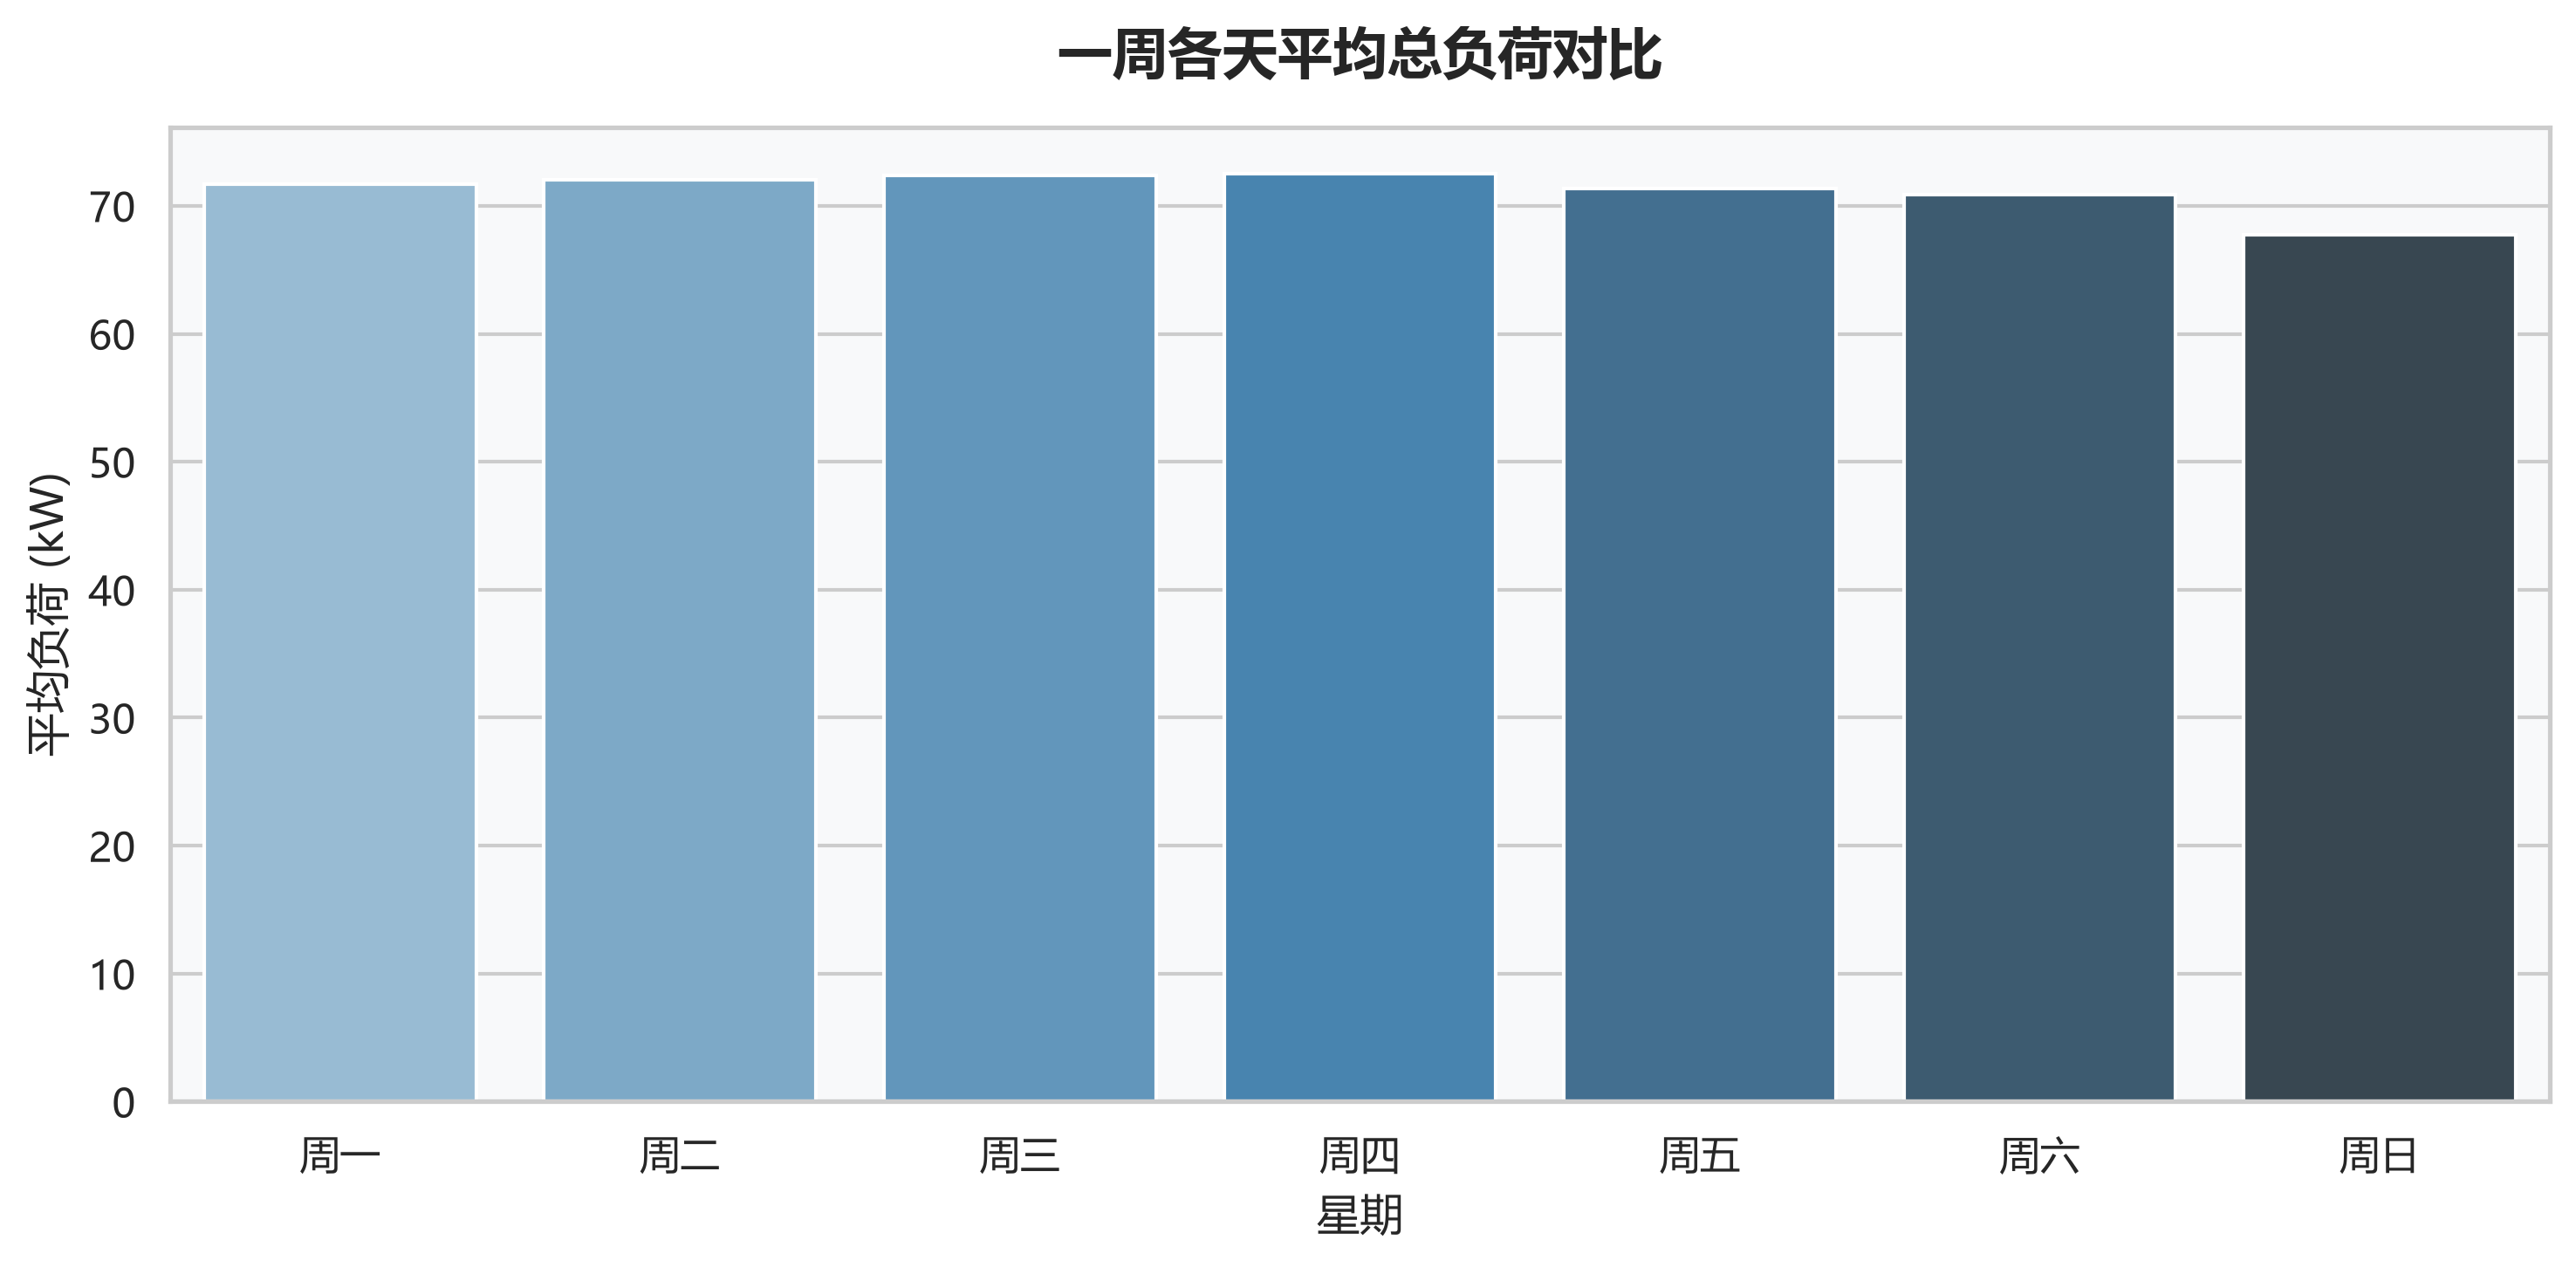

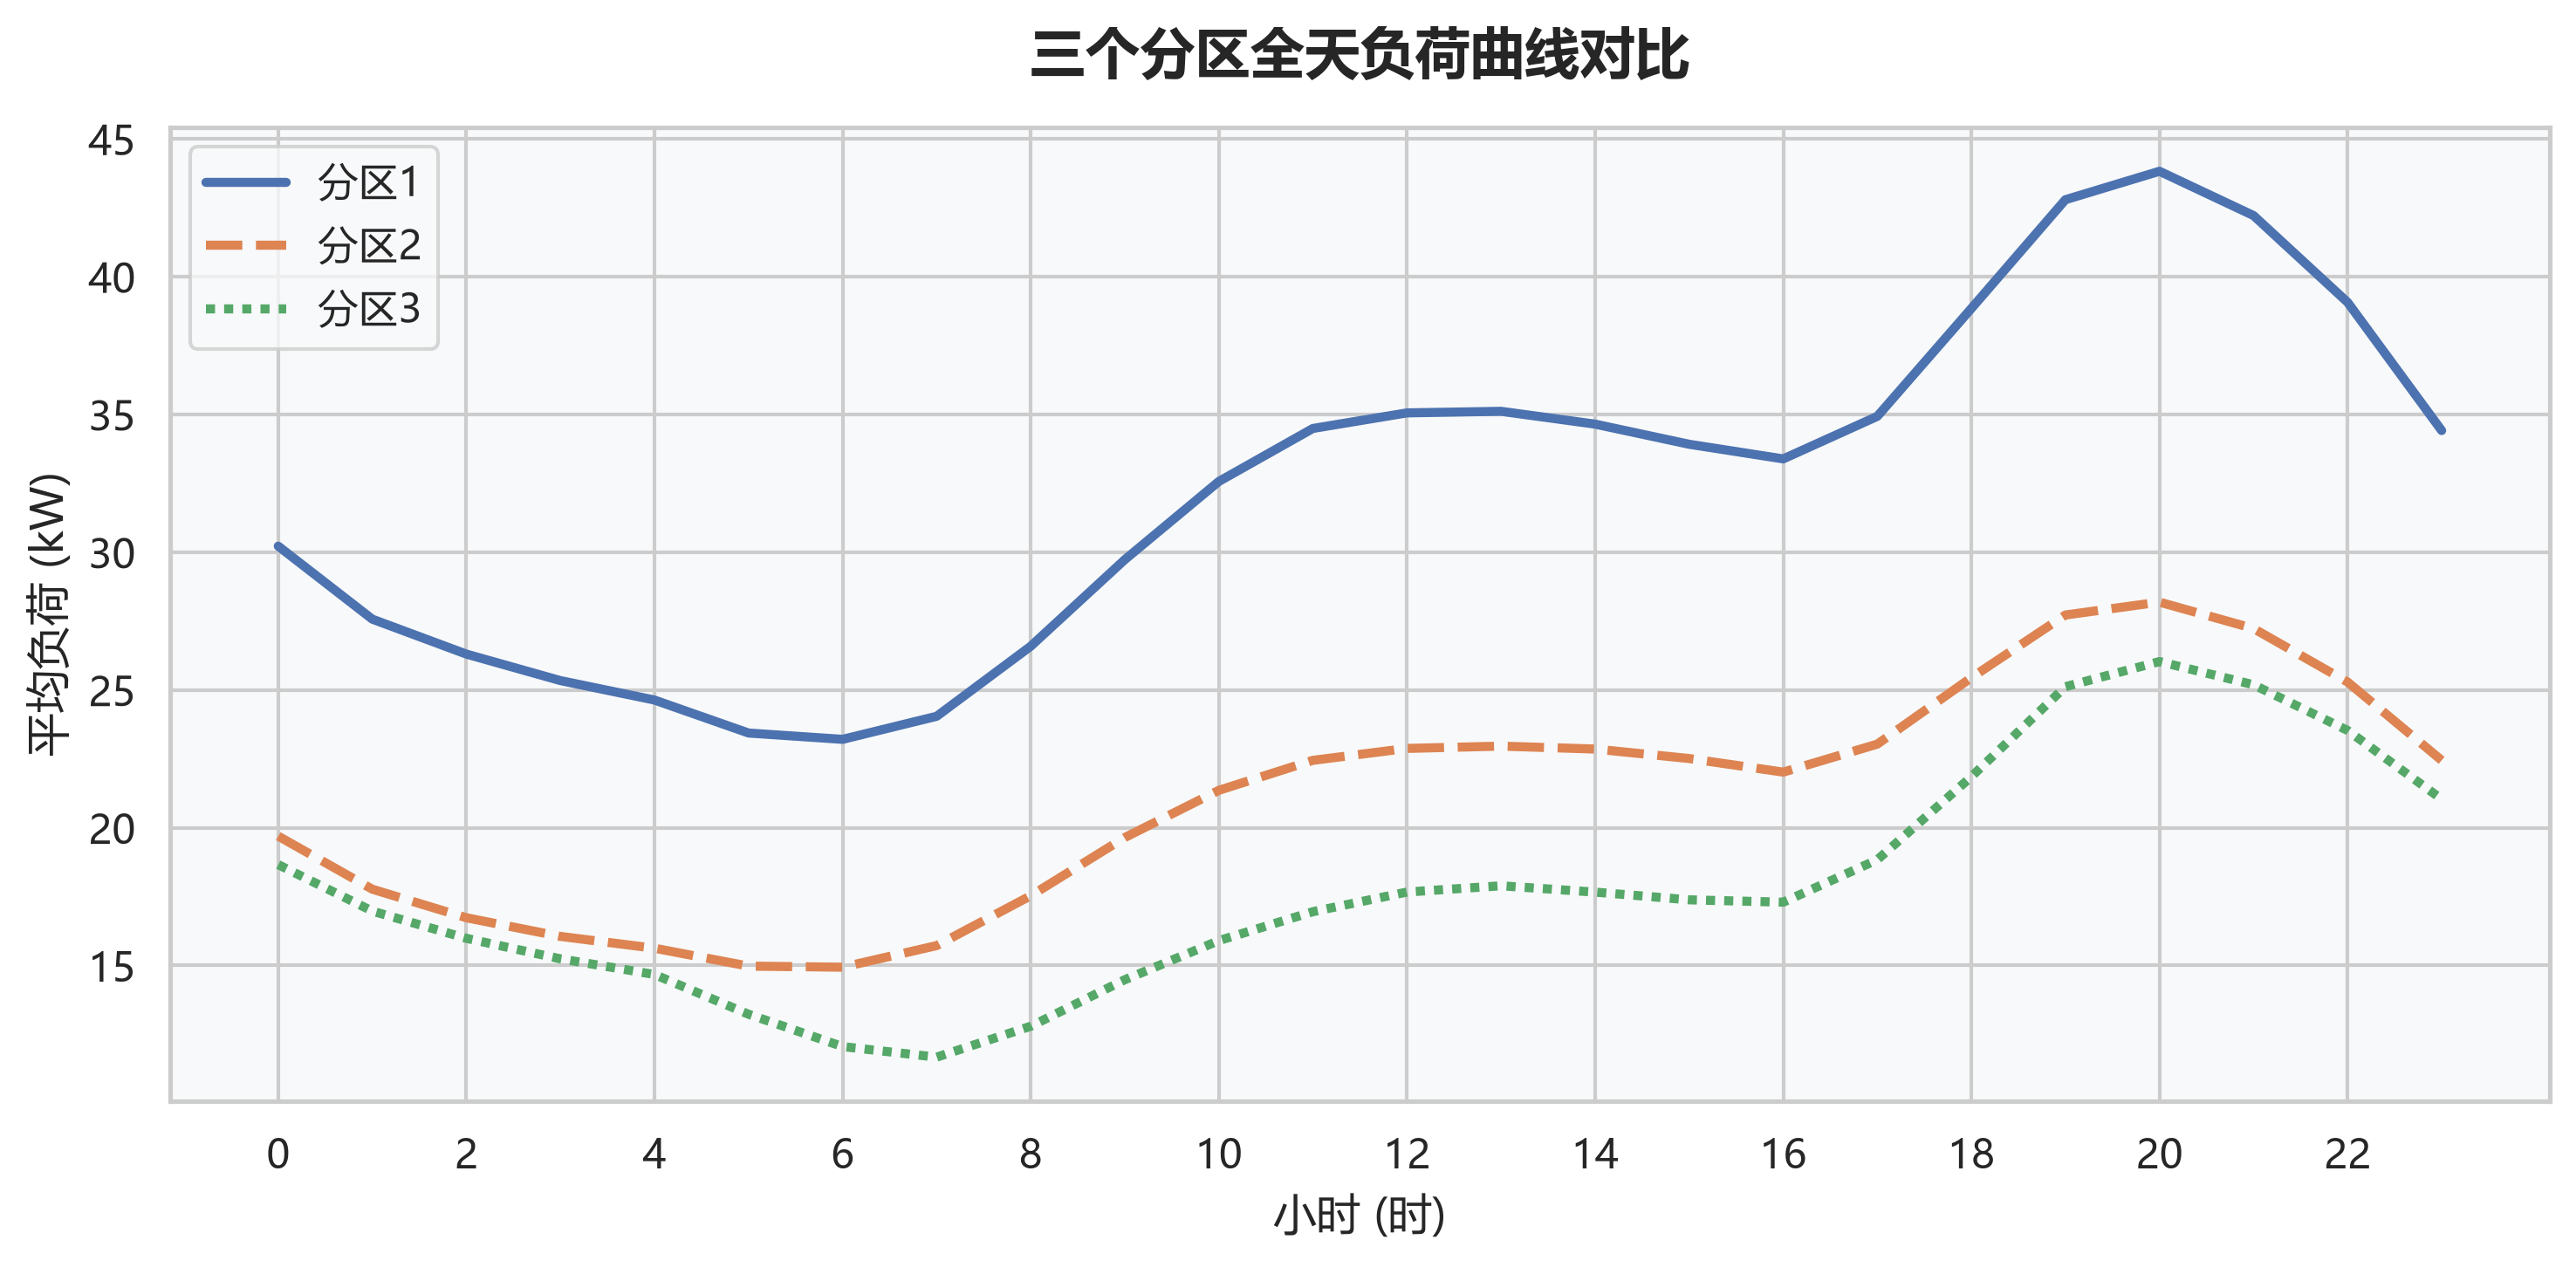

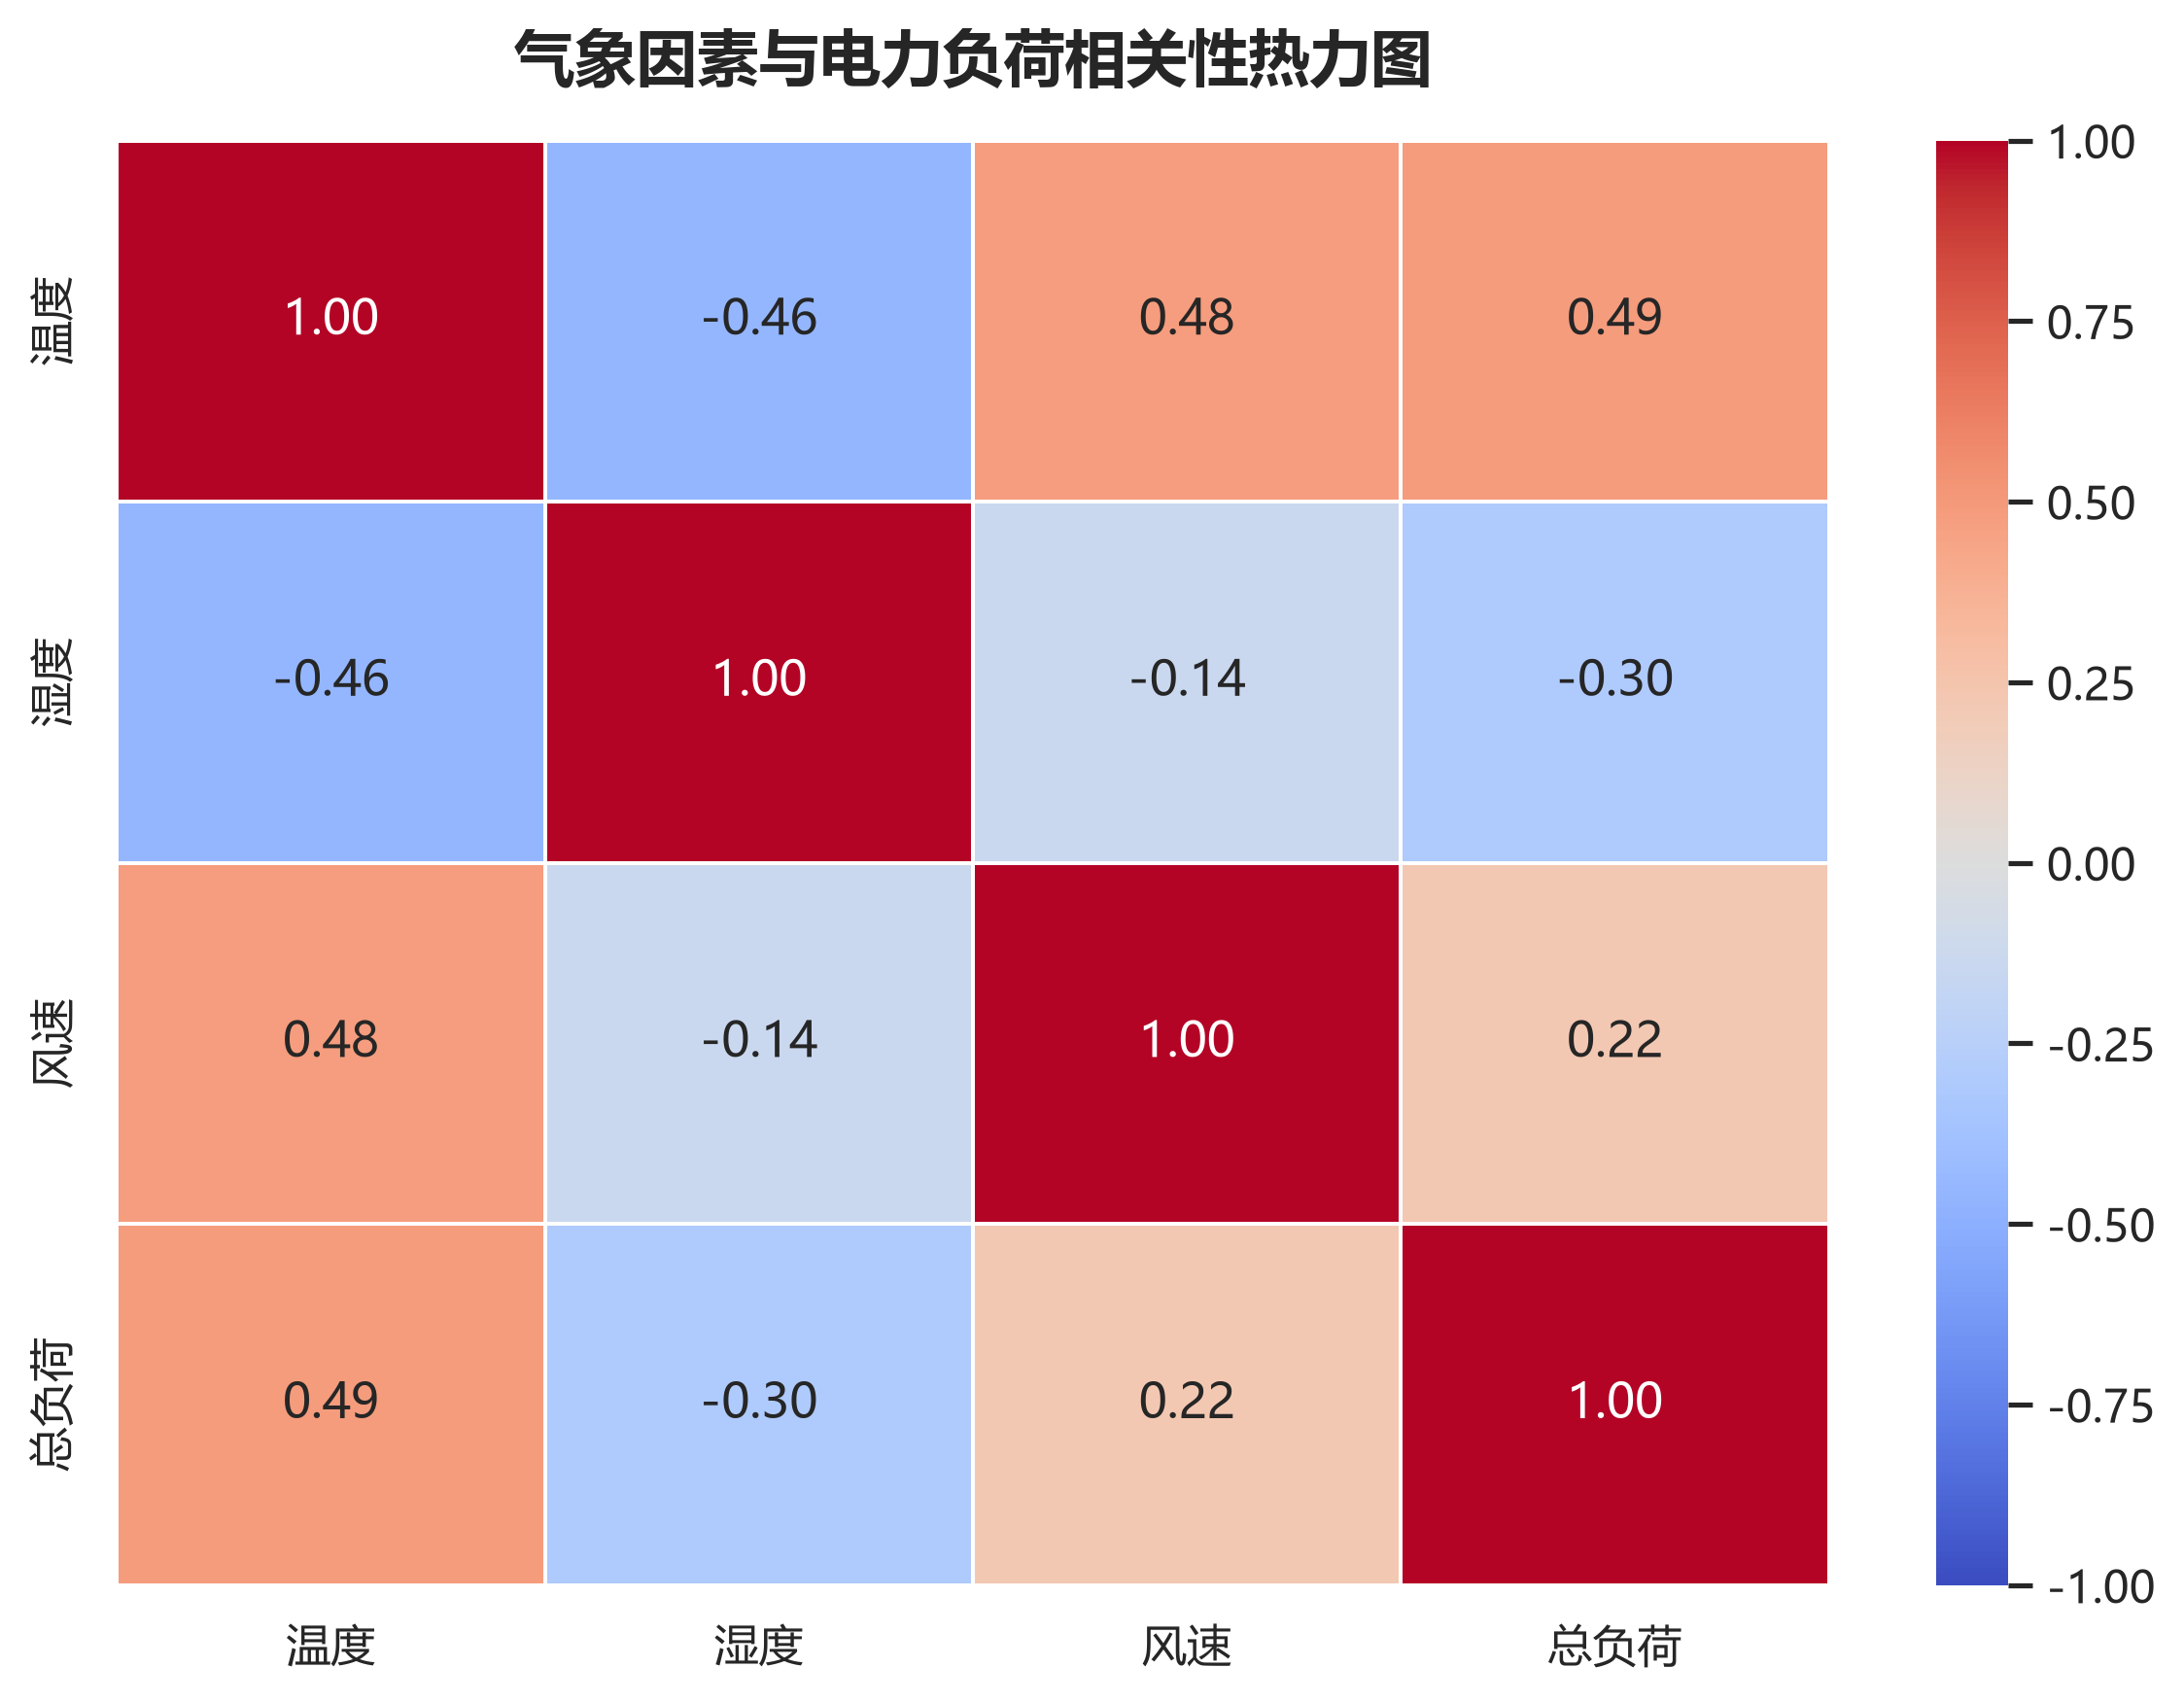

所有图表已生成完毕，请去桌面的 figures 文件夹查看！


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. 设置全局统一风格
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei'] # 解决中文显示
plt.rcParams['axes.unicode_minus'] = False # 解决负号显示
sns.set_theme(style="whitegrid", font="Microsoft YaHei", rc={"axes.facecolor": "#f8f9fa"})

# ==========================================
# 这里直接使用桌面路径（加了 r 防止转义）
# ==========================================
data_path = r"C:\Users\22973\Desktop\power_load_cleaned.csv"
save_dir = r"C:\Users\22973\Desktop\figures"

# 在桌面自动创建一个 figures 文件夹用来存图
os.makedirs(save_dir, exist_ok=True)

# 2. 读取数据
df = pd.read_csv(data_path, parse_dates=['datetime'])
df.set_index('datetime', inplace=True)

# 提取时间特征
df['hour'] = df.index.hour
df['dayofweek'] = df.index.dayofweek  
df['is_weekend'] = df['dayofweek'].apply(lambda x: 1 if x >= 5 else 0)

# ==========================================
# 图 1：日负荷曲线
# ==========================================
plt.figure(figsize=(10, 5), dpi=300)
hourly_avg = df.groupby('hour')['zone_total_power_consumption'].mean() / 1000
sns.lineplot(x=hourly_avg.index, y=hourly_avg.values, marker='o', color='#1f77b4', linewidth=2.5)
plt.title('全天各小时平均总负荷曲线', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('小时 (时)', fontsize=12)
plt.ylabel('平均负荷 (kW)', fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
# 保存到桌面的 figures 文件夹
plt.savefig(os.path.join(save_dir, 'fig01_daily_load.png'), bbox_inches='tight')
plt.show()

# ==========================================
# 图 2：周负荷曲线
# ==========================================
plt.figure(figsize=(10, 5), dpi=300)
days = ['周一', '周二', '周三', '周四', '周五', '周六', '周日']
weekly_avg = df.groupby('dayofweek')['zone_total_power_consumption'].mean() / 1000
sns.barplot(x=days, y=weekly_avg.values, palette='Blues_d')
plt.title('一周各天平均总负荷对比', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('星期', fontsize=12)
plt.ylabel('平均负荷 (kW)', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(save_dir, 'fig02_weekly_load.png'), bbox_inches='tight')
plt.show()

# ==========================================
# 图 3：三个分区负荷对比
# ==========================================
plt.figure(figsize=(10, 5), dpi=300)
zone_cols = ['zone1_power_consumption', 'zone2_power_consumption', 'zone3_power_consumption']
zone_hourly = df.groupby('hour')[zone_cols].mean() / 1000
zone_hourly.columns = ['分区1', '分区2', '分区3']
sns.lineplot(data=zone_hourly, linewidth=2.5)
plt.title('三个分区全天负荷曲线对比', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('小时 (时)', fontsize=12)
plt.ylabel('平均负荷 (kW)', fontsize=12)
plt.xticks(range(0, 24, 2))
plt.legend(title='')
plt.tight_layout()
plt.savefig(os.path.join(save_dir, 'fig03_zone_comparison.png'), bbox_inches='tight')
plt.show()

# ==========================================
# 图 4：气象因素与总负荷相关性热力图
# ==========================================
plt.figure(figsize=(8, 6), dpi=300)
corr_cols = ['temperature', 'humidity', 'wind_speed', 'zone_total_power_consumption']
corr_matrix = df[corr_cols].corr()
corr_matrix.index = ['温度', '湿度', '风速', '总负荷']
corr_matrix.columns = ['温度', '湿度', '风速', '总负荷']

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5, vmin=-1, vmax=1)
plt.title('气象因素与电力负荷相关性热力图', fontsize=15, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(os.path.join(save_dir, 'fig04_correlation_heatmap.png'), bbox_inches='tight')
plt.show()

print("所有图表已生成完毕，请去桌面的 figures 文件夹查看！")